# DS Final Project · Data Retrival from Telegram, real time sites etc


This notebook is draft one and try to retrive data from diff types of online news tools such as Telegram, Ynet etc

**Ehud Hazala:** Telegram.

**Cabaut & Hazala:** Telegram.

**Hamal:** regular site.

**ynet:** regular site.

**Zaka:** Telegram and site. Need to see how to connet between both of those communication tools

## 0 · Setup

In [1]:
!pip install requests beautifulsoup4 trafilatura pandas tqdm lxml_html_clean


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 837.9/837.9 kB 8.5 MB/s  0:00:00
  Attempting uninstall: urllib3
    Found existing installation: urllib3 2.5.0
    Uninstalling urllib3-2.5.0:
      Successfully uninstalled urllib3-2.5.0
  Attempting uninstall: charset_normalizer
    Found existing installation: charset-normalizer 3.4.9
    Uninstalling charset-normalizer-3.4.9:
      Successfully uninstalled charset-normalizer-3.4.9
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9/9 [trafilatura]


In [2]:
!pip install feedparser trafilatura pandas tqdm beautifulsoup4 lxml_html_clean

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [feedparser]


In [ ]:
#OLD version code [6th attempt in previous notebook - V1] to pass the blocking of ynet site

import json
import os
import urllib.parse
import feedparser
import pandas as pd
from bs4 import BeautifulSoup
from google.colab import drive
from tqdm import tqdm

# 0. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

SAVE_DIR = "/content/drive/MyDrive/Liz_BIU-DS23/From_News_to_Action/Test123/"
os.makedirs(SAVE_DIR, exist_ok=True)
FILE_PATH = os.path.join(SAVE_DIR, "israel_accidents_news_corpus.jsonl")

# 1. Comprehensive Hebrew accident search queries
SEARCH_QUERIES = [
    "תאונת דרכים",
    "תאונה קשה בכביש",
    "התנגשות בין כלי רכב",
    "התהפכות רכב",
    "תאונת אופנוע",
    "תאונת אוטובוס",
    "תאונת משאית",
    "פצועים בתאונת דרכים",
    "תאונת פגע וברח"
]

KEYWORDS = [
    "תאונה", "תאונות", "תאונת דרכים", "התנגשות", "התהפכות",
    "פצוע", "פצועים", "לכודים", "רכב", "אופנוע", "אוטובוס", "משאית"
]

collected_articles = []
seen_titles = set()
TARGET_COUNT = 300

print("=" * 70)
print("STARTING ROBUST RSS ACCIDENT CORPUS EXTRACTION")
print("=" * 70)

if os.path.exists(FILE_PATH):
    os.remove(FILE_PATH)

for query in SEARCH_QUERIES:
    if len(collected_articles) >= TARGET_COUNT:
        break

    encoded_query = urllib.parse.quote(query)
    rss_url = f"https://news.google.com/rss/search?q={encoded_query}&hl=he&gl=IL&ceid=IL:he"

    print(f"\n---> Query: '{query}'")
    feed = feedparser.parse(rss_url)

    for item in tqdm(feed.entries, desc="Processing feed items"):
        if len(collected_articles) >= TARGET_COUNT:
            break

        title = getattr(item, 'title', '')
        link = getattr(item, 'link', '')
        published = getattr(item, 'published', 'Unknown')

        source_field = getattr(item, 'source', {})
        publisher = source_field.get('title', 'Israeli News Source') if isinstance(source_field, dict) else 'Israeli News Source'

        if not title or title in seen_titles:
            continue

        # Extract clean text directly from RSS item summary (bypasses all site blocking & None errors)
        raw_summary = getattr(item, 'summary', '')
        soup = BeautifulSoup(raw_summary, "html.parser")
        clean_summary = soup.get_text().strip()

        full_content = f"{title} {clean_summary}"
        matched_kw = [kw for kw in KEYWORDS if kw in full_content]

        if len(clean_summary) > 20 and len(matched_kw) >= 1:
            seen_titles.add(title)
            collected_articles.append(len(collected_articles) + 1)

            article_record = {
                "id": len(collected_articles),
                "title": title,
                "publisher": publisher,
                "url": link,
                "published_date": published,
                "query_used": query,
                "matched_keywords": matched_kw,
                "text": clean_summary
            }

            # Save immediately to Google Drive
            with open(FILE_PATH, "a", encoding="utf-8") as f:
                f.write(json.dumps(article_record, ensure_ascii=False) + "\n")

            print(f" [{len(collected_articles)}/{TARGET_COUNT}] Saved: {title[:55]}...")

print("\n" + "=" * 70)
print(f"SUCCESS! Total articles collected: {len(collected_articles)}")
print(f"Corpus location: {FILE_PATH}")
print("=" * 70)

# Preview data
if os.path.exists(FILE_PATH):
    df = pd.read_json(FILE_PATH, lines=True)
    print("\nSample Preview:")
    print(df[['id', 'publisher', 'title']].head(3))

Mounted at /content/drive
STARTING ROBUST RSS ACCIDENT CORPUS EXTRACTION

---> Query: 'תאונת דרכים'


Processing feed items:  23%|██▎       | 23/101 [00:00<00:00, 186.37it/s]

 [1/300] Saved: הרוג ו-19 פצועים בהתנגשות בין אוטובוס למשאית בצפון - YN...
 [2/300] Saved: נהג אוטובוס בן 61 נהרג בתאונת דרכים בגליל העליון, גבר כ...
 [3/300] Saved: גבר נהרג בתאונה קטלנית בצפון, 19 נפצעו - mako...
 [4/300] Saved: נהג משאית נפצע קשה בתאונה בכביש 6 ופונה במסוק - אמס...
 [5/300] Saved: תאונת דרכים קשה בירושלים: שני הולכי רגל נפגעו, אחד במצב...
 [6/300] Saved: תאונת דרכים בעפולה: רוכב אופנוע בן 30 במצב קשה ופצועה נ...
 [7/300] Saved: שוטרת נפצעה קשה בתאונת דרכים בחיפה; 3 נוספים נפצעו - וו...
 [8/300] Saved: שוטרת נפצעה קשה בתאונה בין רכב לניידת בחיפה - YNET...
 [9/300] Saved: תאונת דרכים קשה ברחוב טובים בחיפה – ארבעה נפגעים - חי פ...
 [10/300] Saved: ארבעה פצועים הלילה בתאונה בחוף שמן. צעירה פונתה במצב קש...
 [11/300] Saved: האברך ר' אליה ארוך נהרג בתאונה בתל אביב - המחדש...
 [12/300] Saved: עוד תאונה בכניסה לאשדוד: בן 72 נפצע בינוני בתאונה בין ש...
 [13/300] Saved: פצוע קשה בתאונה בין שתי משאיות בכביש 6 - סרוגים...
 [14/300] Saved: דובר צה"ל: האירוע בחטיבת בנימין - תאונת

Processing feed items:  68%|██████▊   | 69/101 [00:00<00:00, 215.74it/s]

 [44/300] Saved: "היה לי נס": הזמרת נוי פדלון עברה תאונת דרכים קשה - C14...
 [45/300] Saved: תאונה קטלנית ביפו: בן 29 התנגש בעמוד ונהרג - סרוגים...
 [46/300] Saved: נהג אוטובוס בן 61 נהרג בתאונת דרכים עם משאית - פצועים נ...
 [47/300] Saved: במהלך כיפור: 3 הרוגים בתאונות דרכים, גופה אותרה באום אל...
 [48/300] Saved: הפקח נפצע בירידה מהרכבת — והפניקס סירבה לפצות: זו לא תא...
 [49/300] Saved: הרוג בתאונת דרכים בין אוטובוס לרכב ליד מעלה מכמש - i24N...
 [50/300] Saved: 19 פצועים מהתאונה בצפון הגיעו לזיו: אחד במצב קשה, היתר ...
 [51/300] Saved: אסון בכביש: תאונה קטלנית במעורבות אוטובוס ומשאית - אמס...
 [52/300] Saved: גבר בן 31 במצב קשה בעקבות תאונת אופנוע בכביש 8925 - ווא...
 [53/300] Saved: אישה ו-2 פעוטות נפצעו בתאונת דרכים סמוך למחלף מיתר - וו...
 [54/300] Saved: תאונה מזעזעת: הרוג ועשרות נפגעים בהתנגשות בין אוטובוס ל...
 [55/300] Saved: תאונה באשדוד: צעיר בן 23 נפצע בינוני בתאונה בין שני כלי...
 [56/300] Saved: תאונת דרכים בין 3 כלי רכב בכביש 4 סמוך לצומת מסריק - חי...
 [57/300] Saved: 

Processing feed items: 100%|██████████| 101/101 [00:00<00:00, 218.57it/s]


... (7 outputs left out)

Processing feed items: 100%|██████████| 100/100 [00:00<00:00, 236.81it/s]

 [222/300] Saved: תאונה חזיתית קשה בגליל: שלושה נפצעו קשה - אמס...
 [223/300] Saved: אמש באשדוד: תשעה נפגעים בהתנגשות בין שני כלי רכב - - אש...
 [224/300] Saved: גבר בן 76 במצב בינוני ושניים נוספים במצב קל בעקבות תאונ...
 [225/300] Saved: תאונת דרכים קטלנית בין 2 כלי רכב בכביש 42 - גבר כבן 40 ...
 [226/300] Saved: תאונה קשה בגליל: 2 כלי רכב התנגשו ועלו באש - אמס...
 [227/300] Saved: הרוג ו-3 פצועים בתאונת דרכים בנגב - YNET...
 [228/300] Saved: שתי צעירות במצב בינוני ושניים נוספים במצב קל עקב תאונה ...
 [229/300] Saved: בן 48 במצב בינוני ושניים במצב קל בעקבת תאונה בין שני כל...
 [230/300] Saved: תאונת דרכים בין 2 כלי רכב סמוך לבית אורן - בת 18 נפצעה ...
 [231/300] Saved: 11 נפצעו בתאונה בכניסה לירושלים, בהם אישה במצב בינוני -...
 [232/300] Saved: שני פצועים בתאונה בין שני כלי רכב באשדוד - אשדוד נט...
 [233/300] Saved: תאונה בין מספר כלי רכב בכביש 4: שני פצועים במצב קשה - ה...
 [234/300] Saved: שתי נשים נפצעו בתאונה בין שני כלי רכב בצומת שדרות ירושל...
 [235/300] Saved: גבר כבן 40 לכוד ב


Processing feed items:  53%|█████▎    | 43/81 [00:00<00:00, 264.23it/s]


 [261/300] Saved: גבר בן 31 במצב בינוני בעקבות התהפכות רכב בכביש 25 סמוך ...
 [262/300] Saved: פתרון בעיות בתקרית של התהפכות רכב מיוחד במהלך בדיקת גשר...
 [263/300] Saved: התהפכות רכב בכביש 60: גבר בן 44 נפצע באורח בינוני - C14...
 [264/300] Saved: תיעוד דרמטי מהתאונה הקשה: הרכב טס בצומת, כמעט דרס הולכי...
 [265/300] Saved: נדרשת פעולה דחופה לטיפול בתקרית התהפכות רכב מיוחד על גש...
 [266/300] Saved: "בודקים את כל הכיוונים": פרטים חדשים על התהפכות הרכב מה...
 [267/300] Saved: רכב התהפך באלעד; נער בן 16 פונה לבית החולים - וואלה...
 [268/300] Saved: ירושלים: גנב רכב, ברח מהשוטרים, ביצע תאונה ומת - מקור ר...
 [269/300] Saved: תאונה קטלנית בנגב: גבר כבן 40 נהרג בהתהפכות רכב - היום...
 [270/300] Saved: גבר כבן 50 במצב בינוני ושניים במצב קל עקב התהפכות רכב ב...
 [271/300] Saved: יממה קטלנית בכבישים: 5 הרוגים ב-5 תאונות, באחת מהן הפוג...
 [272/300] Saved: בן 22 במצב בינוני בעקבות התהפכות רכב בכביש 40 - סמוך לצ...
 [273/300] Saved: אישה בת 27 נפצעה באורח בינוני לאחר התהפכות רכב בתל אביב...
 [27

In [ ]:
# Atempt to exract more info - NOT TO USE

import json
import os
import re
import urllib.parse
from datetime import datetime
import feedparser
from bs4 import BeautifulSoup
from google.colab import drive
from tqdm import tqdm

# 0. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# Path configuration
SAVE_DIR = "/content/drive/MyDrive/From_News_to_Action/Test123/"
os.makedirs(SAVE_DIR, exist_ok=True)

# Generate dynamic filename with date and run counter
today_str = datetime.now().strftime("%Y-%m-%d")
counter = 1
while True:
    file_name = f"israel_accidents_corpus_{today_str}_{counter}.json"
    FILE_PATH = os.path.join(SAVE_DIR, file_name)
    if not os.path.exists(FILE_PATH):
        break
    counter += 1

# 1. Comprehensive Hebrew accident search queries
SEARCH_QUERIES = [
    "תאונת דרכים",
    "תאונה קשה בכביש",
    "התנגשות בין כלי רכב",
    "התהפכות רכב",
    "תאונת אופנוע",
    "תאונת אוטובוס",
    "תאונת משאית",
    "פצועים בתאונת דרכים",
    "תאונת פגע וברח"
]

KEYWORDS = [
    "תאונה", "תאונות", "תאונת דרכים", "התנגשות", "התהפכות",
    "פצוע", "פצועים", "לכודים", "רכב", "אופנוע", "אוטובוס", "משאית"
]

def extract_structured_fields(text):
    """Simple heuristic extraction function for specific accident details."""
    # Accident Type detection
    acc_type = "תאונת דרכים כללית"
    if "אופנוע" in text or "קטנוע" in text:
        acc_type = "תאונת אופנוע"
    elif "אוטובוס" in text or "מיניבוס" in text:
        acc_type = "תאונת אוטובוס"
    elif "משאית" in text:
        acc_type = "תאונת משאית"
    elif "התהפכות" in text:
        acc_type = "התהפכות רכב"
    elif "התנגשות" in text:
        acc_type = "התנגשות חזיתית/צדדית"

    # Casualties/Injured detection
    injured_count = "לא צוין במדויק"
    injured_match = re.search(r'(\d+)\s*(?:פצועים|פצועות|נפגעים)', text)
    if injured_match:
        injured_count = int(injured_match.group(1))
    elif "פצוע קשה" in text or "פצוע אנוש" in text or "פצוע קל" in text:
        injured_count = "ישנם פצועים (לא צוין מספר מדויק)"

    # Deaths detection
    death_count = 0
    death_match = re.search(r'(?:הרוג אחד|הרוגים|נקבע מותם של\s*(\d+)|(\d+)\s*הרוגים)', text)
    if "הרוג" in text or "מוות" in text or "נקבע מות" in text:
        if death_match and death_match.group(1):
            death_count = int(death_match.group(1))
        elif death_match and death_match.group(2):
            death_count = int(death_match.group(2))
        else:
            death_count = 1

    # Location heuristic
    location = "לא צוין במדויק"
    loc_match = re.search(r'(?:בכביש\s*\d+|ברחוב\s*[\u0590-\u05ff\"]+\s*[\u0590-\u05ff\"]*|בצומת\s*[\u0590-\u05ff\"]+)', text)
    if loc_match:
        location = loc_match.group(0)

    # Reason/Cause heuristic
    reason = "לא צוין"
    if "איבוד שליטה" in text or "החליק" in text:
        reason = "איבוד שליטה על הרכב"
    elif "מהירות" in text:
        reason = "חשד לנהיגה במהירות מופרזת"
    elif "טלפון" in text or "היסח דעת" in text:
        reason = "היסח דעת / שימוש בטלפון"

    return acc_type, location, injured_count, death_count, reason


collected_articles = []
seen_titles = set()
TARGET_COUNT = 300

print("=" * 70)
print("STARTING SINGLE JSON CORPUS EXTRACTION")
print(f"Target File: {file_name}")
print("=" * 70)

for query in SEARCH_QUERIES:
    if len(collected_articles) >= TARGET_COUNT:
        break

    encoded_query = urllib.parse.quote(query)
    rss_url = f"https://news.google.com/rss/search?q={encoded_query}&hl=he&gl=IL&ceid=IL:he"

    print(f"\n---> Query: '{query}'")
    feed = feedparser.parse(rss_url)

    for item in tqdm(feed.entries, desc="Processing feed items"):
        if len(collected_articles) >= TARGET_COUNT:
            break

        title = getattr(item, 'title', '')
        link = getattr(item, 'link', '')
        published = getattr(item, 'published', 'Unknown')

        source_field = getattr(item, 'source', {})
        publisher = source_field.get('title', 'Israeli News Source') if isinstance(source_field, dict) else 'Israeli News Source'

        if not title or title in seen_titles:
            continue

        raw_summary = getattr(item, 'summary', '')
        soup = BeautifulSoup(raw_summary, "html.parser")
        clean_summary = soup.get_text().strip()

        full_content = f"{title} {clean_summary}"
        matched_kw = [kw for kw in KEYWORDS if kw in full_content]

        if len(clean_summary) > 20 and len(matched_kw) >= 1:
            seen_titles.add(title)

            acc_type, location, injured_count, death_count, reason = extract_structured_fields(full_content)

            article_record = {
                "id": len(collected_articles) + 1,
                "title": title,
                "publisher": publisher,
                "accident_type": acc_type,
                "location": location,
                "number_of_injured": injured_count,
                "number_of_death": death_count,
                "reason_for_accident": reason,
                "url": link,
                "published_date": published,
                "query_used": query,
                "text": clean_summary
            }

            collected_articles.append(article_record)
            print(f" [{len(collected_articles)}/{TARGET_COUNT}] Collected: {title[:55]}...")

# Save all collected articles into one single JSON file at the end
with open(FILE_PATH, "w", encoding="utf-8") as f:
    json.dump(collected_articles, f, ensure_ascii=False, indent=4)

print("\n" + "=" * 70)
print(f"SUCCESS! Total articles saved in single file: {len(collected_articles)}")
print(f"File path: {FILE_PATH}")
print("=" * 70)

Mounted at /content/drive
STARTING CORPUS EXTRACTION & COLLECTION
Target File: israel_accidents_corpus_2026-10-24_1.json

---> Query: 'תאונת דרכים'


Processing feed items: 100%|██████████| 100/100 [00:00<00:00, 4924.51it/s]


 [1/300] Collected: ארבעה נפצעו בתאונת דרכים בכביש 85, בהם אישה במצב בינוני...
 [2/300] Collected: "ביום הבחירות נראה תאונת דרכים חזיתית" - 103FM...
 [3/300] Collected: תאונה קשה סמוך לשריגים: מיניבוס התהפך, 9 בני אדם נפצעו ...
 [4/300] Collected: עלאא קדאדו – סייע לאתר תאונה קשה בחיפה • רגעים שבהם כל ...
 [5/300] Collected: שתי נערות בנות 17 נפצעו בתאונה בין רכב לקורקינט חשמלי ב...
 [6/300] Collected: נהג אוטובוס מחורה נעצר בחשד שדרס למוות ילד בן 8 - ונמלט...
 [7/300] Collected: התאונה בה ילד בן 8 נפגע מאוטובוס ונפצע אנוש: במשטרה בוד...
 [8/300] Collected: שני בני אדם נפצעו בינוני וקל בתאונת דרכים באשדוד - מערי...
 [9/300] Collected: אימה בירושלים: הולכת רגל נלכדה מתחת לאוטובוס - אמס...
 [10/300] Collected: חשד לפגע וברח: הולכת רגל נהרגה בתאונת דרכים קטלנית בירו...
 [11/300] Collected: רוכב אופנוע בן 19 נהרג בתאונת דרכים סמוך לאילת - רשת 13...
 [12/300] Collected: גבר נהרג בתאונה קטלנית בצפון, 19 נפצעו - mako...
 [13/300] Collected: הרוג ו-19 פצועים בהתנגשות בין אוטובוס למשאית בצפון -

Processing feed items: 100%|██████████| 100/100 [00:00<00:00, 7664.47it/s]


 [96/300] Collected: תאונה קטלנית בכביש 90: בן 60 נהרג, שניים נפצעו קשה - מע...
 [97/300] Collected: תאונה קשה בכביש 6: נהג משאית חולץ במצב קשה ולא יציב - J...
 [98/300] Collected: תאונה קשה בכביש 65: ארבעה פצועים, בהם שניים במצב אנוש -...
 [99/300] Collected: נהג משאית נפצע קשה בתאונה בכביש 6 ופונה במסוק - אמס...
 [100/300] Collected: תאונה קטלנית בכביש החוף: אישה כבת 50 נהרגה, גבר נפצע קש...
 [101/300] Collected: תאונה קטלנית בכביש החוף: גבר כבן 60 נהרג, פצועים קשה בז...
 [102/300] Collected: תאונה קשה בכביש 90: חמישה נפצעו, בהם קשה ואנוש - הכביש ...
 [103/300] Collected: הרוג בתאונה בין 4 כלי רכב בכביש 90, שני פצועים במצב קשה...
 [104/300] Collected: תאונה קטלנית בכביש 443: הולך רגל בן 21 נדרס למוות - היו...
 [105/300] Collected: נלכד ברכב: הרוג ושני פצועים בתאונה קשה בכביש 232 - אמס...
 [106/300] Collected: הרוג ושני פצועים קשה בתאונה קטלנית באזור חיפה - YNET...
 [107/300] Collected: תאונה קטלנית בכביש 60: בן 30 נהרג, אדם נוסף נפצע באורח ...
 [108/300] Collected: שני הרוגים בתאונה 

Processing feed items: 100%|██████████| 100/100 [00:00<00:00, 5950.89it/s]


 [176/300] Collected: בת 78 נפצעה בינוני בעקבות תאונה בין 3 כלי רכב בנתניה - ...
 [177/300] Collected: תאונה בין 8 כלי רכב סמוך למחלף עירון: 18 בני אדם נפצעו ...
 [178/300] Collected: תאונה קשה בכביש 35: אישה כבת 60 נפצעה קשה בהתנגשות בין ...
 [179/300] Collected: תאונת חזית במצלמות הכטב"ם: תיעד התנגשות בין כלי רכב והמ...
 [180/300] Collected: זירת התנגשות בין ארבע מכוניות שגרמה לפקק תנועה המשתרע ע...
 [181/300] Collected: תאונה בין שני כלי רכב באזור בית שמש, פצוע קשה פונה במסו...
 [182/300] Collected: תאונה בין שני כלי רכב בקיסריה, גבר כבן 30 במצב קשה - מע...
 [183/300] Collected: הו צ'י מין סיטי: זירת התנגשות בין ארבע מכוניות ברחוב וו...
 [184/300] Collected: עפולה: 10 פצועים במצב קל בעקבות תאונה בין מספר כלי רכב ...
 [185/300] Collected: תאונה בין מספר כלי רכב בכביש 79 סמוך למחלף ציפורי - 6 פ...
 [186/300] Collected: בת 22 במצב בינוני בעקבות תאונת דרכים בין 2 כלי רכב בנוף...
 [187/300] Collected: גבר בן 50 במצב בינוני בעקבות תאונה בין מספר כלי רכב בכב...
 [188/300] Collected: יותר מ

Processing feed items:  52%|█████▏    | 42/81 [00:00<00:00, 4408.10it/s]


 [260/300] Collected: גבר בן 31 במצב בינוני בעקבות התהפכות רכב בכביש 25 סמוך ...
 [261/300] Collected: התהפכות רכב באופקים: בן 19 נפצע בינוני - היום...
 [262/300] Collected: רכב התהפך בירושלים: 8 נפגעים, בהם ילד בן 11 - אמס...
 [263/300] Collected: ילדה בת 4 נפצעה בינוני בהתהפכות רכב בבת ים - C14...
 [264/300] Collected: תיעוד דרמטי מהתאונה הקשה: הרכב טס בצומת, כמעט דרס הולכי...
 [265/300] Collected: רכב התהפך באלעד; נער בן 16 פונה לבית החולים - וואלה...
 [266/300] Collected: נדרשת פעולה דחופה לטיפול בתקרית התהפכות רכב מיוחד על גש...
 [267/300] Collected: "בודקים את כל הכיוונים": פרטים חדשים על התהפכות הרכב מה...
 [268/300] Collected: אחרי תאונה עם משאית, רכב נכנס לחנות בגדים - סרוגים...
 [269/300] Collected: ירושלים: גנב רכב, ברח מהשוטרים, ביצע תאונה ומת - מקור ר...
 [270/300] Collected: התהפכות רכב בכביש 60: גבר בן 44 נפצע באורח בינוני - C14...
 [271/300] Collected: בן 22 במצב בינוני בעקבות התהפכות רכב בכביש 40 - סמוך לצ...
 [272/300] Collected: תאונה קטלנית בכביש 4: אישה נהרגה לאחר 

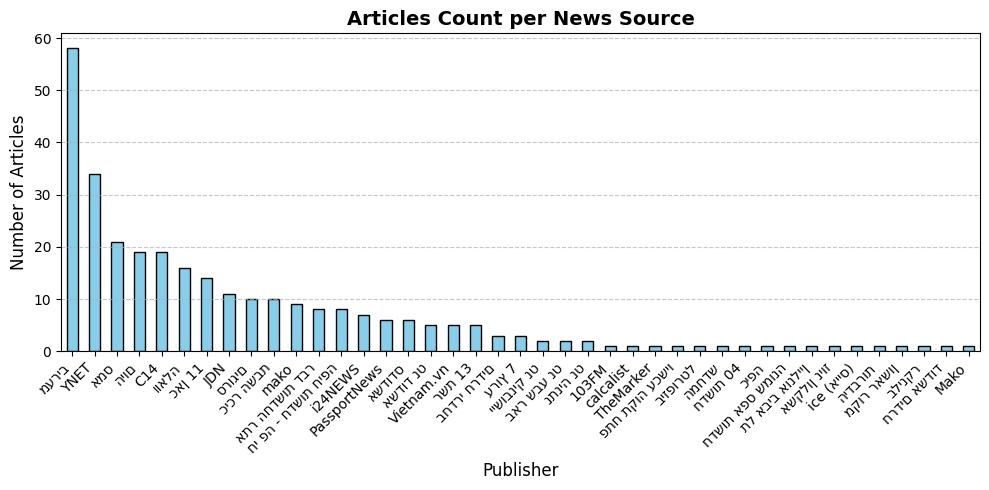

In [3]:
# Combine code with statistic

import json
import os
import re
import urllib.parse
from datetime import datetime
import feedparser
from bs4 import BeautifulSoup
from google.colab import drive
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt

# 0. Mount Google Drive
drive.mount('/content/drive', force_remount=True)

# Path configuration
SAVE_DIR = "/content/drive/MyDrive/From_News_to_Action/Test123/"
os.makedirs(SAVE_DIR, exist_ok=True)

# Generate dynamic filename with date and run counter
today_str = datetime.now().strftime("%Y-%m-%d")
counter = 1
while True:
    file_name = f"israel_accidents_corpus_{today_str}_{counter}.json"
    FILE_PATH = os.path.join(SAVE_DIR, file_name)
    if not os.path.exists(FILE_PATH):
        break
    counter += 1

# 1. Comprehensive Hebrew accident search queries
SEARCH_QUERIES = [
    "תאונת דרכים",
    "תאונה קשה בכביש",
    "התנגשות בין כלי רכב",
    "התהפכות רכב",
    "תאונת אופנוע",
    "תאונת אוטובוס",
    "תאונת משאית",
    "פצועים בתאונת דרכים",
    "תאונת פגע וברח"
]

KEYWORDS = [
    "תאונה", "תאונות", "תאונת דרכים", "התנגשות", "התהפכות",
    "פצוע", "פצועים", "לכודים", "רכב", "אופנוע", "אוטובוס", "משאית"
]

def extract_structured_fields(text):
    """Simple heuristic extraction function for specific accident details."""
    acc_type = "תאונת דרכים כללית"
    if "אופנוע" in text or "קטנוע" in text:
        acc_type = "תאונת אופנוע"
    elif "אוטובוס" in text or "מיניבוס" in text:
        acc_type = "תאונת אוטובוס"
    elif "משאית" in text:
        acc_type = "תאונת משאית"
    elif "התהפכות" in text:
        acc_type = "התהפכות רכב"
    elif "התנגשות" in text:
        acc_type = "התנגשות חזיתית/צדדית"

    injured_count = "לא צוין במדויק"
    injured_match = re.search(r'(\d+)\s*(?:פצועים|פצועות|נפגעים)', text)
    if injured_match:
        injured_count = int(injured_match.group(1))
    elif "פצוע קשה" in text or "פצוע אנוש" in text or "פצוע קל" in text:
        injured_count = "ישנם פצועים (לא צוין מספר מדויק)"

    death_count = 0
    death_match = re.search(r'(?:הרוג אחד|הרוגים|נקבע מותם של\s*(\d+)|(\d+)\s*הרוגים)', text)
    if "הרוג" in text or "מוות" in text or "נקבע מות" in text:
        if death_match and death_match.group(1):
            death_count = int(death_match.group(1))
        elif death_match and death_match.group(2):
            death_count = int(death_match.group(2))
        else:
            death_count = 1

    location = "לא צוין במדויק"
    loc_match = re.search(r'(?:בכביש\s*\d+|ברחוב\s*[\u0590-\u05ff\"]+\s*[\u0590-\u05ff\"]*|בצומת\s*[\u0590-\u05ff\"]+)', text)
    if loc_match:
        location = loc_match.group(0)

    reason = "לא צוין"
    if "איבוד שליטה" in text or "החליק" in text:
        reason = "איבוד שליטה על הרכב"
    elif "מהירות" in text:
        reason = "חשד לנהיגה במהירות מופרזת"
    elif "טלפון" in text or "היסח דעת" in text:
        reason = "היסח דעת / שימוש בטלפון"

    return acc_type, location, injured_count, death_count, reason


collected_articles = []
seen_titles = set()
TARGET_COUNT = 300

print("=" * 70)
print("STARTING CORPUS EXTRACTION & COLLECTION")
print(f"Target File: {file_name}")
print("=" * 70)

for query in SEARCH_QUERIES:
    if len(collected_articles) >= TARGET_COUNT:
        break

    encoded_query = urllib.parse.quote(query)
    rss_url = f"https://news.google.com/rss/search?q={encoded_query}&hl=he&gl=IL&ceid=IL:he"

    print(f"\n---> Query: '{query}'")
    feed = feedparser.parse(rss_url)

    for item in tqdm(feed.entries, desc="Processing feed items"):
        if len(collected_articles) >= TARGET_COUNT:
            break

        title = getattr(item, 'title', '')
        link = getattr(item, 'link', '')
        published = getattr(item, 'published', 'Unknown')

        source_field = getattr(item, 'source', {})
        publisher = source_field.get('title', 'Israeli News Source') if isinstance(source_field, dict) else 'Israeli News Source'

        if not title or title in seen_titles:
            continue

        raw_summary = getattr(item, 'summary', '')
        soup = BeautifulSoup(raw_summary, "html.parser")
        clean_summary = soup.get_text().strip()

        full_content = f"{title} {clean_summary}"
        matched_kw = [kw for kw in KEYWORDS if kw in full_content]

        if len(clean_summary) > 20 and len(matched_kw) >= 1:
            seen_titles.add(title)

            acc_type, location, injured_count, death_count, reason = extract_structured_fields(full_content)

            article_record = {
                "id": len(collected_articles) + 1,
                "title": title,
                "publisher": publisher,
                "accident_type": acc_type,
                "location": location,
                "number_of_injured": injured_count,
                "number_of_death": death_count,
                "reason_for_accident": reason,
                "url": link,
                "published_date": published,
                "query_used": query,
                "text": clean_summary
            }

            collected_articles.append(article_record)
            print(f" [{len(collected_articles)}/{TARGET_COUNT}] Collected: {title[:55]}...")

# Save all collected articles into the single JSON file
with open(FILE_PATH, "w", encoding="utf-8") as f:
    json.dump(collected_articles, f, ensure_ascii=False, indent=4)

print("\n" + "=" * 70)
print(f"SUCCESS! Total articles saved: {len(collected_articles)}")
print(f"File path: {FILE_PATH}")
print("=" * 70)

# ===================================================================
# AUTOMATED PUBLISHER SOURCE DISTRIBUTION ANALYSIS
# ===================================================================
print("\n" + "=" * 70)
print("GENERATING PUBLISHER SOURCE DISTRIBUTION SUMMARY")
print("=" * 70)

df = pd.read_json(FILE_PATH)
publisher_counts = df['publisher'].value_counts()

print("\nNumber of articles extracted from each source:")
print("-" * 40)
for publisher, count in publisher_counts.items():
    print(f"• {publisher}: {count} articles")

print("-" * 40)
print(f"Total unique publishers: {len(publisher_counts)}")
print(f"Total corpus size: {len(df)}")
print("=" * 70)

# Plot visual breakdown
plt.figure(figsize=(10, 5))
publisher_counts.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title("Articles Count per News Source", fontsize=14, fontweight='bold')
plt.xlabel("Publisher", fontsize=12)
plt.ylabel("Number of Articles", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()